In [1]:
# Load packages
import scanpy as sc
import numpy as np
import seaborn as sns
import anndata
import matplotlib.pyplot as plt

In [2]:
merged_adata = anndata.read_h5ad("merged_adata.h5ad")

In [3]:
merged_adata 

AnnData object with n_obs × n_vars = 31444 × 33538
    obs: 'n_genes', 'sample'
    layers: None (.X)

In [4]:
merged_adata.obs.head()

,n_genes,sample
AAACATACAATGCC-1_ctrl,874,ctrl
AAACATACATTTCC-1_ctrl,896,ctrl
AAACATACCAGAAA-1_ctrl,725,ctrl
AAACATACCAGCTA-1_ctrl,979,ctrl
AAACATACCATGCA-1_ctrl,362,ctrl


In [4]:
# Calculate QC metrics
sc.pp.calculate_qc_metrics(merged_adata,
                           percent_top = None,
                           log1p = False,
                           inplace = True)
# Explore merged metadata
merged_adata.obs.head()

,n_genes,sample,n_genes_by_counts,total_counts
AAACATACAATGCC-1_ctrl,874,ctrl,874,2344.0
AAACATACATTTCC-1_ctrl,896,ctrl,896,3125.0
AAACATACCAGAAA-1_ctrl,725,ctrl,725,2578.0
AAACATACCAGCTA-1_ctrl,979,ctrl,979,3261.0
AAACATACCATGCA-1_ctrl,362,ctrl,362,746.0


In [5]:
# Add cell IDs to metadata
merged_adata.obs["cells"] = merged_adata.obs.index

merged_adata.obs.head()

,n_genes,sample,n_genes_by_counts,total_counts,cells
AAACATACAATGCC-1_ctrl,874,ctrl,874,2344.0,AAACATACAATGCC-1_ctrl
AAACATACATTTCC-1_ctrl,896,ctrl,896,3125.0,AAACATACATTTCC-1_ctrl
AAACATACCAGAAA-1_ctrl,725,ctrl,725,2578.0,AAACATACCAGAAA-1_ctrl
AAACATACCAGCTA-1_ctrl,979,ctrl,979,3261.0,AAACATACCAGCTA-1_ctrl
AAACATACCATGCA-1_ctrl,362,ctrl,362,746.0,AAACATACCATGCA-1_ctrl


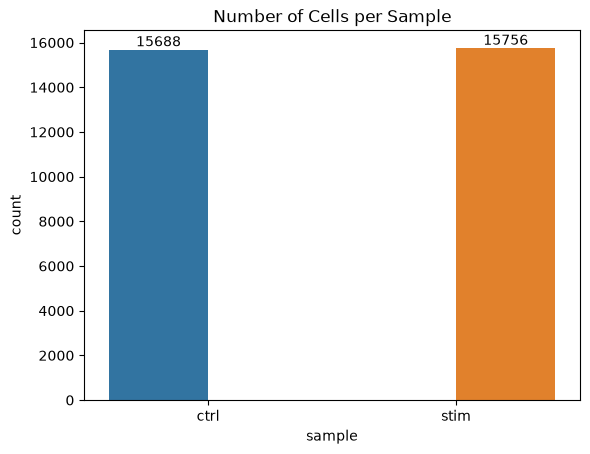

In [6]:
fig, ax = plt.subplots()
ax = sns.countplot(data = merged_adata.obs, 
                   x = "sample", hue = "sample",
                   ax = ax)
ax.set_title("Number of Cells per Sample")

# Add counts above the bars
for container in ax.containers:
    ax.bar_label(container)

plt.show()

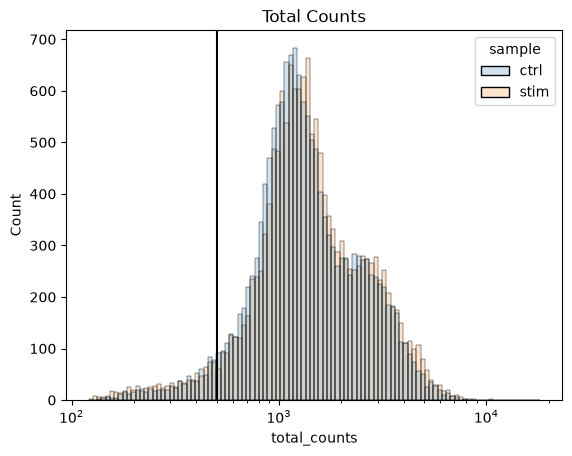

In [7]:
# Visualize the number UMIs/transcripts per cell
fig, ax = plt.subplots()
ax = sns.histplot(merged_adata.obs, 
                  x = "total_counts", 
                  hue = "sample",
                  log_scale = True, # apply log scale to counts
                  alpha = 0.2, ax = ax)
ax.set_title("Total Counts")

# Add line showing potential threshold
ax.axvline(500, color="black")
plt.show()

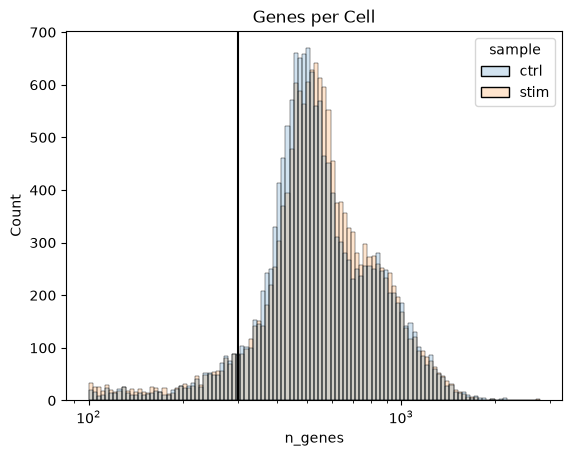

In [9]:
# Visualize the distribution of genes detected per cell via histogram
ax = sns.histplot(merged_adata.obs, 
                  x = "n_genes", 
                  hue = "sample",
                  log_scale = True, # apply log scale to counts
                  alpha = 0.2)
ax.set_title("Genes per Cell")

# Add line showing potential threshold
ax.axvline(300, color = "black")
plt.show()

In [8]:
merged_adata.obs["log10GenesPerUMI"] = np.log10(merged_adata.obs["n_genes"]) / np.log10(merged_adata.obs["total_counts"])

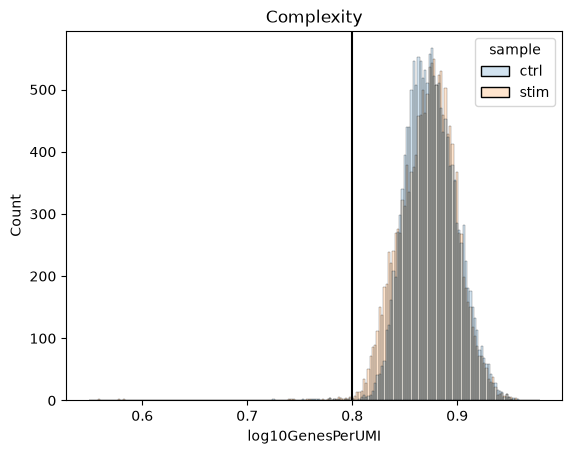

In [9]:
ax = sns.histplot(merged_adata.obs, 
                  x = "log10GenesPerUMI", hue = "sample",
                  alpha = 0.2)
ax.set_title("Complexity")

# Add line showing potential threshold
ax.axvline(0.8, color = "black")
plt.show()

In [10]:
merged_adata.var.head()

,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts
MIR1302-2HG,0,0.000000,100.000000,0.0
FAM138A,0,0.000000,100.000000,0.0
OR4F5,0,0.000000,100.000000,0.0
AL627309.1,12,0.000382,99.961837,12.0
AL627309.3,1,0.000032,99.996820,1.0


In [11]:
# Identify mitochondrial genes
mito_genes = merged_adata.var_names.str.startswith('MT-')
merged_adata.var['mito'] = mito_genes

merged_adata.var.head()

,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,mito
MIR1302-2HG,0,0.000000,100.000000,0.0,False
FAM138A,0,0.000000,100.000000,0.0,False
OR4F5,0,0.000000,100.000000,0.0,False
AL627309.1,12,0.000382,99.961837,12.0,False
AL627309.3,1,0.000032,99.996820,1.0,False


In [12]:
# Calculate number of counts coming from mito_genes
sc.pp.calculate_qc_metrics(merged_adata, 
                           qc_vars = ["mito"],
                           inplace = True)

# We want the value as a ratio
merged_adata.obs["mito_ratio"] = merged_adata.obs["pct_counts_mito"] / 100

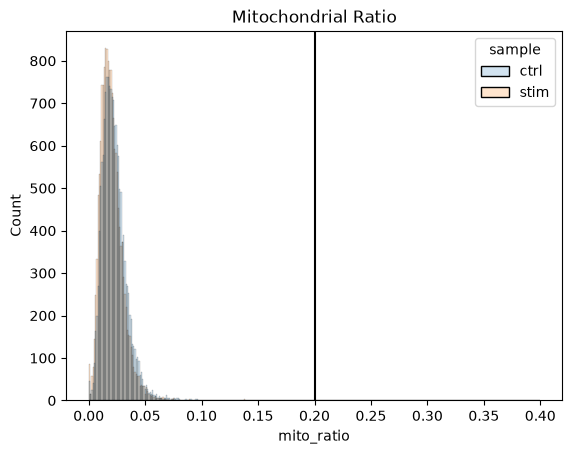

In [13]:
# Histogram of mitochondrial ratio
ax = sns.histplot(merged_adata.obs, 
                  x = "mito_ratio", hue = "sample",
                  alpha = 0.2)
ax.set_title("Mitochondrial Ratio")

# Add line showing potential threshold
ax.axvline(0.2, color = "black")
plt.show()

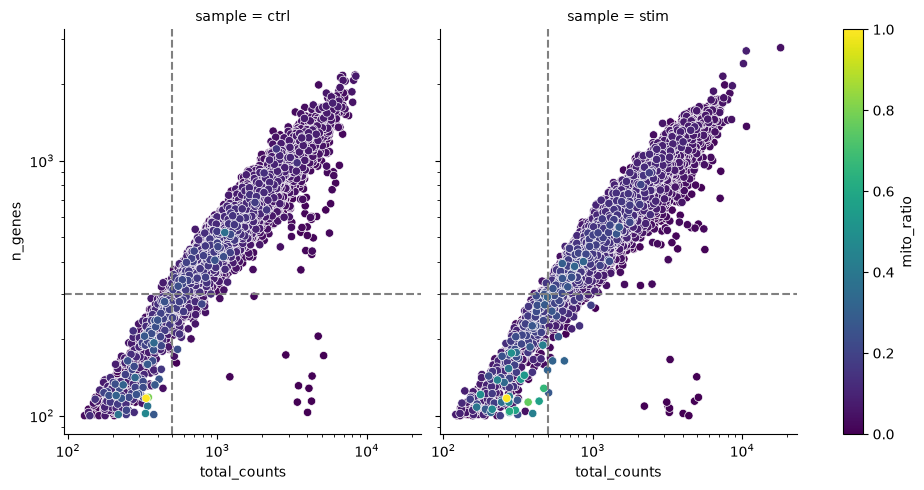

In [14]:
# Order dataset so values are plotted 
# such that largest values are on top
meta = merged_adata.obs.sort_values('mito_ratio', ascending=True)

g = sns.FacetGrid(meta, col="sample", height=5)
g.map_dataframe(sns.scatterplot, 
                x = "total_counts", 
                y = "n_genes", 
                hue = "mito_ratio",
                palette = "viridis")

# Scale x,y axes by log10
for ax in g.axes.flat:
    ax.set(xscale = "log", yscale = "log")

# Add threshold lines
g.refline(x = 500, y = 300)

# Add colorbar for the legend 
sm = g.axes[0, 0].collections[0]
plt.colorbar(sm, ax = g.axes, 
             label = "mito_ratio")
plt.show()    

In [15]:
filtered_adata = merged_adata[merged_adata.obs["total_counts"] >= 500]
filtered_adata = filtered_adata[filtered_adata.obs["n_genes"] >= 250]
filtered_adata = filtered_adata[filtered_adata.obs["log10GenesPerUMI"] >= 0.8]
filtered_adata = filtered_adata[filtered_adata.obs["mito_ratio"] < 0.2]

filtered_adata

View of AnnData object with n_obs × n_vars = 29629 × 33538
    obs: 'n_genes', 'sample', 'n_genes_by_counts', 'total_counts', 'cells', 'log10GenesPerUMI', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'mito_ratio'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'mito', 'log1p_mean_counts', 'log1p_total_counts'
    layers: None (.X)

In [16]:
# Remove lowly expressed genes
sc.pp.filter_genes(filtered_adata, 
                   inplace = True, 
                   min_counts = 10)

filtered_adata

C:\Users\user\anaconda3\envs\pyscRNA\Lib\site-packages\scanpy\preprocessing\_simple.py:278: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var["n_counts"] = number


AnnData object with n_obs × n_vars = 29629 × 14167
    obs: 'n_genes', 'sample', 'n_genes_by_counts', 'total_counts', 'cells', 'log10GenesPerUMI', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'mito_ratio'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'mito', 'log1p_mean_counts', 'log1p_total_counts', 'n_counts'
    layers: None (.X)

In [20]:
filtered_adata.var.head()

,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,mito,log1p_mean_counts,log1p_total_counts,n_counts
AL627309.1,12,0.000382,99.961837,12.0,False,0.000382,2.564949,12.0
AL669831.5,99,0.003212,99.685155,101.0,False,0.003207,4.624973,99.0
LINC00115,177,0.005915,99.437095,186.0,False,0.005898,5.231109,170.0
FAM41C,136,0.004389,99.567485,138.0,False,0.004379,4.934474,134.0
NOC2L,2019,0.069934,93.579061,2199.0,False,0.067597,7.696213,2139.0


In [21]:
# Create h5ad object to load at any time
filtered_adata.write_h5ad("data/filtered_adata.h5ad")